In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

In [30]:
# Finden der zu der max Stromstärke gehörende Kapazität
# geht davon aus, dass es nur einen gemessenen Wert für die maximale Stromstärke gibt
def find_C_0(kapazität, stromstärke):
    I_max = stromstärke.max()
    for i in range(len(kapazität)):
        if (stromstärke[i] == I_max):
            return kapazität[i]

In [31]:
# gibt die Stelle im Array aus wo C_0 steht
def find_C_0_stelle(c_0, kapazität_array):
    for i in range(len(kapazität_array)):
        if (c_0 == kapazität_array[i]):
            return i

# Serienresonanzkreis

## Unsicherheiten der Messwerte

### Messung Spannung
    - die Spannung wurde vom Multimeter abgelesen
        - abs Grenzen: $\pm$ 0.05 mV
        - Unsicherheit vom Hersteller: ± (0,7% + 2) Echteffektiv
            - 0,7% vom Messwert + 2 auf die letzte gemessene Stelle
            - https://www.fluke.com/de-de/produkt/elektrische-pruefungen/digitalmultimeter/fluke-87v
### Messung Kapazität  
    - die Kapazität hat eine Unsicherheit von XXX, Angabe durch den Hersteller
    - https://www.farnell.com/datasheets/2366684.pdf
    - 1% Unsicherheit
### "Messung" Frequenz 
    - Schwankungen am Frequenzgenerator wurden angezeigt, abs. Grenzen von \pm 50 Hz

In [32]:
# Frequenz 
f_0 = 1000 # in Herz abs. Grenzen +/- 50 Hz, entstehen durch Schwankungen 
u_f_0 = 50/(2*np.sqrt(6))
w_0 = 2*np.pi * f_0
u_w_0 = 2*np.pi*u_f_0
print(w_0)
print(u_w_0)
wid_10_ohm = 10.0

6283.185307179586
64.12749150809321


In [33]:
# Daten einlesen 0 Ohm
nC_0_ohm = np.array([2.1, 4.1, 6.1, 8.1, 10.1, 10.2, 10.3, 10.4, 10.5, 10.6, 10.7, 10.8, 10.9, 11.0, 11.1, 11.2, 11.3, 11.4, 11.5, 11.6, 11.8, 12.0, 12.2, 12.5, 12.8, 13.1, 14.1, 16.1, 20.1, 30.1, 40.1, 100.1, 600.0, 11111.0]) # in nF
mU_0_ohm = np.array([0.1, 0.5, 1.1, 2.5, 10.4, 12.8, 14.5, 16.5, 18.7, 24.5, 31.4, 41.2, 50.5, 42.6, 36.0, 21.8, 18.1, 15.3, 13.3, 12.0, 10.0, 8.6, 7.6, 6.4, 5.2, 4.7, 3.6, 2.6, 1.9, 1.4, 1.2, 1, 0.8, 0.8]) # in mV
U_0_ohm = mU_0_ohm*1e-03 # nun in V
C_0_ohm = nC_0_ohm*1e-09 # nun in Farad
# Berechnung der Stromstärke
I_0_ohm = U_0_ohm/wid_10_ohm # in Ampere
print("0 ohm Maximum bei Imax = " + str(I_0_ohm.max())+ " und C =" + str(find_C_0(C_0_ohm, I_0_ohm)))

0 ohm Maximum bei Imax = 0.005050000000000001 und C =1.0900000000000002e-08


In [34]:
# 203.8 Ohm
nC_203_8_ohm = np.array([2.1, 3.1, 4.1, 5.1, 7.1, 8.1, 9.1, 9.2, 9.3, 9.4, 9.5, 9.6, 9.7, 9.8, 9.9, 10.0, 10.1, 10.2, 10.3, 10.4, 10.5, 10.6, 10.7, 10.8, 10.9, 11.0, 11.1, 11.2, 11.3, 11.4, 11.5, 11.6, 11.7, 11.8, 12.0, 12.4, 12.8, 13.1, 14.2, 16.1, 18.1, 20.0, 30.1, 40.1, 60.1, 11111.0]) # in nF
mU_203_8_ohm  = np.array([0.1, 0.3, 0.5, 0.8, 1.8, 2.9, 5.5, 5.9, 6.4, 7.0, 7.7, 8.4, 9.3, 10.4, 11.6, 13.2, 14.7, 17.1, 21.7, 23.4, 26.2, 27.5, 27.0, 25.0, 22.4, 19.8, 15.8, 14.2, 12.4, 11.4, 10.4, 9.7, 9.0, 8.4, 7.4, 6.1, 5.2, 4.7, 3.7, 2.7, 2.2, 1.9, 1.6, 1.4, 1.0, 0.9]) # in mV
U_203_8_ohm = mU_203_8_ohm*1e-03
C_203_8_ohm = nC_203_8_ohm*1e-09
# Berechnung der Stromstärke 
I_203_8_ohm = U_203_8_ohm/wid_10_ohm
print("203.8 ohm Maximum bei Imax = " + str(I_203_8_ohm.max())+ " und C =" + str(find_C_0(C_203_8_ohm, I_203_8_ohm)))

203.8 ohm Maximum bei Imax = 0.00275 und C =1.06e-08


In [35]:
# 509.4 Ohm
nC_509_4_ohm = np.array([2.1, 3.1, 4.1, 5.1, 6.1, 7.1, 7.5, 8.1, 8.4, 8.6, 8.7, 8.8, 8.9, 9.0, 9.1, 9.2, 9.3, 9.4, 9.5, 9.6, 9.7, 9.8, 9.9, 10, 10.1, 10.2, 10.3, 10.4, 10.5, 10.6, 10.7, 10.8, 10.9, 11.0, 11.1, 11.3, 11.5, 11.7, 11.9, 12.1, 12.4, 12.7, 13.0, 13.4, 14.1, 16.1, 18.1, 22.1, 28.1, 31.1, 51.1, 11111.0]) # in nF
mU_509_4_ohm = np.array([0.1, 0.3, 0.6, 0.9, 1.4, 2.2, 2.7, 3.9, 4.8, 5.5, 6.0, 6.6, 7.1, 7.7, 8.5, 9.4, 10.4, 11.5, 12.8, 13.9, 15.0, 16.0, 16.4, 16.5, 16.1, 15.2, 14.1, 13.1, 12.0, 11.1, 10.3, 9.5, 8.9, 8.3, 7.4, 6.6, 6.0, 5.5, 5.1, 4.8, 4.3, 3.9, 3.7, 3.4, 2.9, 2.3, 1.9, 1.6, 1.3, 1.2, 1.0, 0.8]) # in mV
U_509_4_ohm = mU_509_4_ohm*1e-03
C_509_4_ohm = nC_509_4_ohm*1e-09
# Berechnung der Stromstärke
I_509_4_ohm = U_509_4_ohm/wid_10_ohm
print("509.4 ohm Maximum bei Imax = " + str(I_509_4_ohm.max())+ " und C =" + str(find_C_0(C_509_4_ohm, I_509_4_ohm)))

509.4 ohm Maximum bei Imax = 0.00165 und C =1e-08


### Unsicherheit Widerstände

In [36]:
u_ohm_dig = 0.1/(2*np.sqrt(3)) # Unsicherheit beim Multimeter abs. Grenzen +/- 0.05
# Berechnung Unsicherheit Widerstand
wid_10_ohm = 10.0 
wid_0_ohm = 0
wid_203_8_ohm = 203.8
wid_509_4_ohm = 509.4

u_10_ohm_her = wid_10_ohm*0.002 + 0.1
u_203_8_ohm_her = wid_203_8_ohm*0.002 + 0.1
u_509_4_ohm_her = wid_509_4_ohm*0.002 + 0.1

u_10_ohm = np.sqrt(u_ohm_dig**2 + u_10_ohm_her**2)
u_0_ohm = 0
u_203_8_ohm = np.sqrt(u_ohm_dig**2 + u_203_8_ohm_her**2)
u_509_4_ohm = np.sqrt(u_ohm_dig**2 + u_509_4_ohm_her**2)
print(u_10_ohm) # 0.1234
print(u_203_8_ohm) # 0.5084
print(u_509_4_ohm) #1.119

0.12342339054382413
0.5084201936718618
1.1191723608691082


In [37]:
# Unsicherheit der Innenwiderstände
R_gr = 52.2 # in Ohm
R_kl = 18.9 

u_R_gr = np.sqrt((R_gr*0.002 + 0.1)**2 + u_ohm_dig**2 )
u_R_kl = np.sqrt((R_kl*0.002 + 0.1)**2 + u_ohm_dig**2 )
print(u_R_gr)
print(u_R_kl)

0.20642842181573093
0.1407912402578134


In [38]:
# Unsicherheit Anzeige Gerät
u_U_dig = (0.1/(2*np.sqrt(3)))*1e-03 # in V

In [39]:
# Berechnung Unsicherheiten Spannung
u_U_mess_0_ohm =  U_0_ohm*0.007 + 2*1e-04
u_U_mess_203_8_ohm = U_203_8_ohm*0.007 + 2*1e-04
u_U_mess_509_4_ohm = U_509_4_ohm*0.007 + 2*1e-04

In [40]:
# direkt Kombinierte Unsicherheit für Spannung
u_U_0_ohm = np.sqrt(u_U_dig**2 + u_U_mess_0_ohm**2)
u_U_203_8_ohm = np.sqrt(u_U_dig**2 + u_U_mess_203_8_ohm**2)
u_U_509_4_ohm = np.sqrt(u_U_dig**2 + u_U_mess_509_4_ohm**2)

### Fehlerfortpflanzung Stromstärke 
Die Stromstärke I mit der Gleichung $I = \frac{U}{R}$ hängt von zwei Größen ab, die beide Unsicherheitsbelastet sind. Demnach berechnet sich der Fehler für die Stromstärke wie folgt:
$$
u_I = \sqrt{\left( \frac{1}{R}\cdot u_U\right)^2 + \left(- \frac{U}{R^2} \cdot u_R \right)^2}
$$

In [41]:
# Berechnung Unsicherheit Stromstärke
u_I_0_ohm = np.sqrt(((1/wid_10_ohm)*u_U_0_ohm)**2 + ((U_0_ohm/wid_10_ohm**2)*u_10_ohm)**2)
u_I_203_8_ohm = np.sqrt(((1/wid_10_ohm)*u_U_203_8_ohm)**2 + ((U_203_8_ohm/wid_10_ohm**2)*u_10_ohm)**2)
u_I_509_4_ohm = np.sqrt(((1/wid_10_ohm)*u_U_509_4_ohm)**2 + ((U_509_4_ohm/wid_10_ohm**2)*u_10_ohm)**2)

### Unsicherheit Kapazität
Die Messunsicherheit für jeden einzelnen Wert errechnet sich durch Messwert $\cdot$ 0.01

In [42]:
u_C_0_ohm = C_0_ohm*0.01
u_C_203_8_ohm = C_203_8_ohm*0.01
u_C_509_4_ohm = C_509_4_ohm*0.01

### Berechnung der Induktivität L
Formel zur Berechnung der Induktivität:
$$
L = \frac{1}{\omega_0^2 C}
$$
C bekannt durch Fkt. find_c_0

In [43]:
# Funktion zur Berechnung der Induktivität
def calc_L(kap):
    result = 1/(w_0**2 * kap)
    return result

### Unsicherheitsbetrachtung Induktivität
Die Induktivität hängt von den mit unsicherheitsbelasteten Größen $\omega_0$ und $C$ ab. Mit Fehlerfortpflanzung:
$$
u_L = \sqrt{\left(-\frac{2}{\omega_0^3 C} \cdot u_{\omega_0} \right)^2 + \left(- \frac{1}{\omega_0^2 C^2} \cdot u_C \right)^2}
$$

In [44]:
# Partielle Ableitung von L nach w_0
def partial_L_w_0(kap, w_0 = w_0, u_w_0 = u_w_0):
    temp = (2/(w_0**3 * kap))*u_w_0
    return temp

In [45]:
# Partielle Ableitung von L nach C
# a ist das Array aus dem kap kommt und u_a das zugehörige Unsicherheitsarray
def partial_L_kap(kap, kap_array,  u_kap_array, w_0 = w_0):
    temp = (1/(w_0**2 * kap**2)) * u_kap_array[find_C_0_stelle(kap, kap_array)]
    return temp

In [46]:
def calc_u_L(kap, kap_array, u_kap_array):
    result = np.sqrt(partial_L_w_0(kap)**2 + partial_L_kap(kap, kap_array, u_kap_array)**2)
    return result

### Bestimmung von C_1 und C_2 (Serienresonanzkreis)


In [81]:
# Bestimmen von c_1 und c_2 
def find_c_1(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_max = stromstärke.max()/np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] < I_max < stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    m = (I_i_1 - I_i)/(c_i_1 - c_i)
    n = I_i -m*c_i
    c_1 = (I_max - n)/m
    return c_1

# Unsicherheit von c_1
def find_u_c_1(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_max = stromstärke.max()/np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] < I_max < stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    grenzen = c_i_1 - c_i
    return (grenzen/(2*np.sqrt(6)))

def find_c_2(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_max = stromstärke.max()/np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] > I_max > stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    m = (I_i_1 - I_i)/(c_i_1 - c_i)
    n = I_i -m*c_i
    c_2 = (I_max - n)/m
    return c_2

# Unsicherheit von c_2
def find_u_c_2(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_max = stromstärke.max()/np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] > I_max > stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    grenzen = c_i - c_i_1
    return grenzen/(2*np.sqrt(6))

# find_c_i-1 und c_i+1
def find_c_around(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_max = stromstärke.max()/np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] < I_max < stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    return str(c_i) +" "+ str(c_i_1)

### Verlustwiderstand R berechnen
$$
R_V = \frac{1}{2 \omega_0}\left(\frac{1}{C_2}- \frac{1}{C_1}\right)
$$

### Innenwiderstand R_i berechnen
$$
R_i = R_p - R_V
$$

### Unsicherheit Verlustwiderstand
$$
u_{R_V} = \sqrt{\left(-\frac{1}{2\omega_0^2}\left(\frac{1}{C_2}- \frac{1}{C_1}\right) \cdot u_{\omega_0} \right)^2 + \left(-\frac{1}{2 \omega_0 C_{2}^2} \cdot u_{C_2}\right)^2 + \left(\frac{1}{2 \omega_0 C_{1}^2} \cdot u_{C_1} \right)^2}
$$

### Unsicherheit Innenwiderstand
$$
u_{R_i} = \sqrt{(- u_{R_V})^2 + (- u_{R_p})^2 }
$$

In [48]:
def calc_verlustwiderstand(kapazität, stromstärke):
    temp = 1/(find_c_2(kapazität, stromstärke)) - 1/(find_c_1(kapazität, stromstärke))
    result = (1/(2*w_0))*temp
    return result

In [49]:
# Partielle Ableitung von R_V nach omega_0
def partial_R_V_w_0(c_1, c_2,  w_0 = w_0, u_w_0 = u_w_0):
    temp = (1/(2*w_0**2))*(1/c_2 - 1/c_1)*u_w_0
    return temp   

In [50]:
# Partielle Ableitung von R_V nach c_2
def partial_R_V_c_2(c_2, u_c_2, w_0 = w_0, u_w_0 = u_w_0):
    temp = u_c_2/(2 * w_0 * c_2**2)
    return temp

In [51]:
# Partielle Ableitung von R_V nach c_1
def partial_R_V_c_1(c_1, u_c_1, w_0 = w_0, u_w_0 = u_w_0):
    temp = u_c_1/(2 * w_0 * c_1**2)
    return temp        

In [52]:
# Unsicherheits berechnung von R
def calc_u_R_V(c_1, u_c_1, c_2, u_c_2,  w_0 = w_0, u_w_0 = u_w_0):
    temp1 = partial_R_V_w_0(c_1, c_2)**2
    temp2 = partial_R_V_c_1(c_1, u_c_1)**2 + temp1
    temp3 = partial_R_V_c_2(c_2, u_c_2)**2 + temp2
    result = np.sqrt(temp3)
    return result

In [53]:
# Berechnung Innenwiderstand
def calc_innen_wid(r_p, r_V):
    return r_p - r_V

In [54]:
# Berechnung Unsicherheit Innenwiderstand
def calc_u_innen_wid(u_r_p, u_r_V):
    temp = np.sqrt(u_r_p**2 + u_r_V**2)
    return temp

### Diagramm erste Messung (0 Ohm)

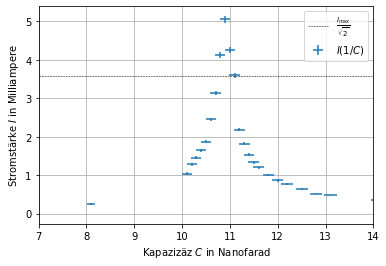

In [55]:
%matplotlib inline
#plt.plot(C_0_ohm/(1e-09), I_0_ohm/(1e-03), color = "lightblue", zorder = 1)
plt.errorbar(C_0_ohm/(1e-09), I_0_ohm/(1e-03), xerr = u_C_0_ohm/(1e-09), yerr = u_I_0_ohm/(1e-03), marker = "", linestyle = "", zorder=2, label = "$I(1/C)$")
plt.axhline(y=(I_0_ohm.max()/np.sqrt(2)/(1e-03)), color="black", linestyle="--", linewidth = 0.5, label = r'$\frac{I_{max}}{\sqrt{2}}$')
plt.xlim(7, 14)
plt.xlabel("Kapazizäz $C$ in Nanofarad")
plt.ylabel("Stromstärke $I$ in Milliampere")
plt.grid()
plt.legend()
plt.savefig('Serienresonanzkreis 0 Ohm.pdf')

In [82]:
c_0_0_ohm = find_C_0(C_0_ohm, I_0_ohm)
print("Die Induktivität beträgt: " +str(calc_L(c_0_0_ohm)))
print("Die Unsicherheit dieses Wertes beträg:" +str(calc_u_L(c_0_0_ohm, C_0_ohm, u_C_0_ohm)))
print(c_0_0_ohm)
print()
print("Der Verlustwiderstand beträgt: " + str(calc_verlustwiderstand(C_0_ohm, I_0_ohm)))

#Unsicherheiten der Punkte C_1 und C_2:
"""
Der ....
"""
r_v_0_ohm = calc_verlustwiderstand(C_0_ohm, I_0_ohm)
u_r_v_0_ohm = calc_u_R_V(find_c_1(C_0_ohm, I_0_ohm), find_u_c_1(C_0_ohm, I_0_ohm), find_c_2(C_0_ohm, I_0_ohm), find_u_c_2(C_0_ohm, I_0_ohm))
print("Die Unsicherheit des Verlustwiderstandes beträgt: " + str(calc_u_R_V(find_c_1(C_0_ohm, I_0_ohm), find_u_c_1(C_0_ohm, I_0_ohm), find_c_2(C_0_ohm, I_0_ohm), find_u_c_2(C_0_ohm, I_0_ohm))))
print()
print(find_c_1(C_0_ohm, I_0_ohm))
print(find_c_2(C_0_ohm, I_0_ohm))
print(find_c_around(C_0_ohm, I_0_ohm))
print()
r_v_0_ohm = -calc_verlustwiderstand(C_0_ohm, I_0_ohm)
u_r_v_0_ohm = calc_u_R_V(find_c_1(C_0_ohm, I_0_ohm), find_u_c_1(C_0_ohm, I_0_ohm), find_c_2(C_0_ohm, I_0_ohm), find_u_c_2(C_0_ohm, I_0_ohm))
print("Innenwiderstand: " + str(calc_innen_wid(wid_0_ohm, r_v_0_ohm)))
print("Unsicherheit Innenwiderstand: "+ str(calc_u_innen_wid(u_0_ohm, u_r_v_0_ohm)))

Die Induktivität beträgt: 2.323880358769215
Die Unsicherheit dieses Wertes beträg:0.052822504291585394
1.0900000000000002e-08

Der Verlustwiderstand beträgt: -238.89355870353012
Die Unsicherheit des Verlustwiderstandes beträgt: 19.43316510329256

1.0743968290305312e-08
1.1102050053169572e-08
1.07e-08 1.08e-08

Innenwiderstand: -238.89355870353012
Unsicherheit Innenwiderstand: 19.43316510329256


### Diagramm zweite Messung (203.8 Ohm)

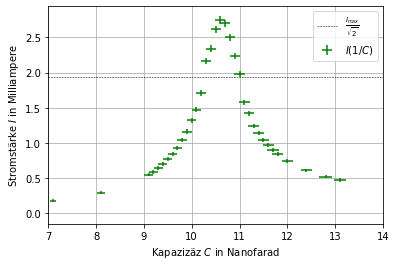

In [57]:
#plt.plot(C_203_8_ohm/(1e-09), I_203_8_ohm/(1e-03), color = "lightgreen", zorder = 1)
plt.errorbar(C_203_8_ohm/(1e-09), I_203_8_ohm/(1e-03), xerr = u_C_203_8_ohm/(1e-09), yerr = u_I_203_8_ohm/(1e-03), marker = "", linestyle = "", zorder=2, color="green", label = "$I(1/C)$")
plt.axhline(y=(I_203_8_ohm.max()/np.sqrt(2)/(1e-03)), color="black", linestyle="--", linewidth = 0.5, label = r'$\frac{I_{max}}{\sqrt{2}}$')
plt.xlim(7, 14)
plt.xlabel("Kapazizäz $C$ in Nanofarad")
plt.ylabel("Stromstärke $I$ in Milliampere")
plt.grid()
plt.legend()
plt.savefig('Serienresonanzkreis 203.8 Ohm.pdf')

In [58]:
c_0_203_8_ohm = find_C_0(C_203_8_ohm, I_203_8_ohm)
print("Die Induktivität beträgt: " +str(calc_L(c_0_203_8_ohm)))
print("Die Unsicherheit dieses Wertes beträgt: "+ str(calc_u_L(c_0_203_8_ohm, C_0_ohm, u_C_203_8_ohm)))
print(c_0_203_8_ohm)
print()
print("Der Verlustwiderstand beträgt: " + str(np.abs(calc_verlustwiderstand(C_203_8_ohm, I_203_8_ohm))))
print("Die Unsicherheit des Verlustwiderstandes beträgt: " + str(calc_u_R_V(find_c_1(C_203_8_ohm, I_203_8_ohm), find_u_c_1(C_203_8_ohm, I_203_8_ohm), find_c_2(C_203_8_ohm, I_203_8_ohm), find_u_c_2(C_203_8_ohm, I_203_8_ohm))))
print()
print(find_c_1(C_203_8_ohm, I_203_8_ohm))
print(find_c_2(C_203_8_ohm, I_203_8_ohm))
print()
r_v_203_8_ohm = np.abs(calc_verlustwiderstand(C_203_8_ohm, I_203_8_ohm))
u_r_v_203_8_ohm = calc_u_R_V(find_c_1(C_203_8_ohm, I_203_8_ohm), find_u_c_1(C_203_8_ohm, I_203_8_ohm), find_c_2(C_203_8_ohm, I_203_8_ohm), find_u_c_2(C_203_8_ohm, I_203_8_ohm))
print("Innenwiderstand: " + str(np.abs(calc_innen_wid(wid_203_8_ohm, r_v_203_8_ohm))))
print("Unsicherheit Innenwiderstand: "+ str(calc_u_innen_wid(u_203_8_ohm, u_r_v_203_8_ohm)))

Die Induktivität beträgt: 2.389650557602306
Die Unsicherheit dieses Wertes beträgt: 0.05318283963039754
1.06e-08

Der Verlustwiderstand beträgt: 534.4169935627536
Die Unsicherheit des Verlustwiderstandes beträgt: 21.173993626281373

1.0250987749622393e-08
1.100886408793425e-08

Innenwiderstand: 330.61699356275363
Unsicherheit Innenwiderstand: 21.180096722610536


### Diagramm zweite Messung (509.4 Ohm)

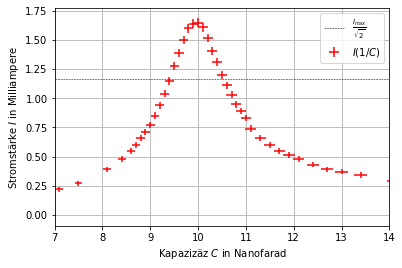

In [59]:
#plt.plot(C_509_4_ohm/(1e-09), I_509_4_ohm/(1e-03), color = "coral", zorder = 1)
plt.errorbar(C_509_4_ohm/(1e-09), I_509_4_ohm/(1e-03), xerr = u_C_509_4_ohm/(1e-09), yerr = u_I_509_4_ohm/(1e-03), marker = "", linestyle = "", zorder=2, color="red", label = "$I(1/C)$")
plt.axhline(y=(I_509_4_ohm.max()/np.sqrt(2)/(1e-03)), color="black", linestyle="--", linewidth = 0.5, label = r'$\frac{I_{max}}{\sqrt{2}}$')
plt.xlim(7, 14)
plt.xlabel("Kapazizäz $C$ in Nanofarad")
plt.ylabel("Stromstärke $I$ in Milliampere")
plt.grid()
plt.legend()
plt.savefig('Serienresonanzkreis 509.4 Ohm.pdf')

In [60]:
c_0_509_4_ohm = find_C_0(C_509_4_ohm, I_509_4_ohm)
print("Die Induktivität beträgt: " +str(calc_L(c_0_509_4_ohm)))
print("Die Unsicherheit dieses Wertes beträgt: "+ str(calc_u_L(c_0_509_4_ohm, C_509_4_ohm, u_C_509_4_ohm)))
print(c_0_509_4_ohm)
print("Der Verlustwiderstand beträgt: " + str(calc_verlustwiderstand(C_509_4_ohm, I_509_4_ohm)))
print("Die Unsicherheit des Verlustwiderstandes beträgt: " + str(calc_u_R_V(find_c_1(C_509_4_ohm, I_509_4_ohm), find_u_c_1(C_509_4_ohm, I_509_4_ohm), find_c_2(C_509_4_ohm, I_509_4_ohm), find_u_c_2(C_509_4_ohm, I_509_4_ohm))))
print()
print(find_c_1(C_509_4_ohm, I_509_4_ohm))
print(find_c_2(C_509_4_ohm, I_509_4_ohm))
print(w_0)
print()
r_v_509_4_ohm = np.abs(calc_verlustwiderstand(C_509_4_ohm, I_509_4_ohm))
u_r_v_509_4_ohm = calc_u_R_V(find_c_1(C_509_4_ohm, I_509_4_ohm), find_u_c_1(C_509_4_ohm, I_509_4_ohm), find_c_2(C_509_4_ohm, I_509_4_ohm), find_u_c_2(C_509_4_ohm, I_509_4_ohm))
print("Innenwiderstand: " + str(np.abs(calc_innen_wid(wid_509_4_ohm, r_v_509_4_ohm))))
print("Unsicherheit Innenwiderstand: "+ str(calc_u_innen_wid(u_509_4_ohm, u_r_v_509_4_ohm)))

Die Induktivität beträgt: 2.5330295910584444
Die Unsicherheit dieses Wertes beträgt: 0.057576529677828094
1e-08
Der Verlustwiderstand beträgt: -901.9016699249795
Die Unsicherheit des Verlustwiderstandes beträgt: 25.196971487993327

9.412866299198313e-09
1.0536970901157998e-08
6283.185307179586

Innenwiderstand: 392.5016699249795
Unsicherheit Innenwiderstand: 25.22181434671348


### Innenwiderstand
$$
R = R_V + R_i
$$

## Parallelresonanzkreis

In [61]:
# Finden der zu der max Stromstärke gehörende Kapazität
# geht davon aus, dass es nur einen gemessenen Wert für die maximale Stromstärke gibt
def find_C_0_V2(kapazität, stromstärke):
    I_min = stromstärke.min()
    for i in range(len(kapazität)):
        if (stromstärke[i] == I_min):
            return kapazität[i]

In [62]:
# Daten einlesen inf Ohm
nC_inf_ohm = np.array([0.1, 20.1, 40.1, 60.1, 80.1, 100.1, 120.1, 140.1, 160.1, 180.1, 200.1, 220.1, 240.1, 245.1, 250.1, 255.1, 258.1, 260.1, 261.1, 262.1, 263.1, 264.1, 265.1, 266.1, 267.1, 268.1, 269.1, 270.1, 271.1, 272.1, 273.1, 275.1, 277.1, 279.1, 281.1, 284.1, 285.1, 286.1, 287.1, 288.1, 289.1, 290.1, 291.1, 293.1, 296.1, 298.1, 300.1, 303.1, 306.1, 308.1, 310.1, 313.1, 315.1, 317.1, 319.1, 321.1, 323.1, 326.1, 328.1, 331.1, 334.1, 337.1, 340.1, 343.1, 346.1, 349.1, 355.1, 358.1, 361.1, 367.1, 370.1, 375.1, 380.1, 390.1, 430.1, 450.1, 500.1, 600.1]) # in nF
mU_inf_ohm = np.array([62.1, 57.8, 53.4, 49, 44.7, 40.4, 36.3, 32, 27.6, 23.3, 19, 14.5, 10.4, 9.4, 8.3, 7.4, 6.8, 6.5, 6.3, 6.1, 6, 5.8, 5.7, 5.5, 5.4, 5.2, 5.1, 5, 4.9, 4.8, 4.7, 4.5, 4.4, 4.2, 4.1, 3.9, 3.9, 3.8, 3.9, 3.9, 4, 4.1, 4.1, 4.3, 4.6, 4.8, 5.1, 5.4, 5.9, 6.2, 6.6, 7.2, 7.6, 7.9, 8.3, 8.7, 9.1, 9.7, 10.1, 10.7, 11.3, 12, 12.6, 13.2, 13.8, 14.5, 15.8, 16.5, 17.1, 18.4, 19, 20.1, 21.2, 23.4, 32.2, 36.6, 47.4, 68.6]) # in mV
U_inf_ohm = mU_inf_ohm*1e-03 # nun in V
C_inf_ohm = nC_inf_ohm*1e-09 # nun in Farad
# Berechnung der Stromstärke
I_inf_ohm = U_inf_ohm/wid_10_ohm # in Ampere
print(len(mU_inf_ohm))
print(len(nC_inf_ohm))
print("Inf ohm Minimum bei Imin = " + str(I_inf_ohm.min())+ " und C =" + str(find_C_0_V2(C_inf_ohm, I_inf_ohm)))

78
78
Inf ohm Minimum bei Imin = 0.00038 und C =2.8610000000000005e-07


In [63]:
# Daten 9.9k ohm
nC_9_9_k_ohm = np.array([50.1, 150.1, 180.1, 200.1, 210.1, 220.1,  230.1, 235.1, 240.1, 245.1, 250.1, 255.1, 260.1, 262.1, 263.1, 264.1, 265.1, 266.1, 267.1, 268.1, 270.1, 272.1, 274.1, 276.1, 278.1, 280.1, 287.1, 289.1, 299.1, 310.1, 315.1, 320.1, 330.1, 335.1, 340.1, 350.1, 360.1, 380.1, 400.1, 430.1, 460.1, 500.1, 550.1]) # in nF
mU_9_9_k_ohm = np.array([52.8, 31.1, 24.7, 20.5, 18.2, 16.2, 14.3, 13.3, 12.4, 11.6, 10.7, 9.9, 9.3, 9, 8.9, 8.9, 8.8, 8.7, 8.6, 8.3, 8.3, 8.1, 8, 7.9, 7.8, 7.6, 7.4, 7.7, 8.2, 9.3, 10, 10.8, 12.5, 13.5, 14.4, 16.5, 18.6, 22.7, 27, 33.7, 40.4, 51.2, 60.1]) # in mV
U_9_9_k_ohm = mU_9_9_k_ohm*1e-03 # nun in V
C_9_9_k_ohm = nC_9_9_k_ohm*1e-09 # nun in Farad
# Berechnung der Stromstärke
I_9_9_k_ohm = U_9_9_k_ohm/wid_10_ohm # in Ampere
print(len(U_9_9_k_ohm))
print(len(C_9_9_k_ohm))
print("9.9k Ohm Minimum bei Imin = " + str(I_9_9_k_ohm.min())+ " und C =" + str(find_C_0_V2(C_9_9_k_ohm, I_9_9_k_ohm)))

43
43
9.9k Ohm Minimum bei Imin = 0.00074 und C =2.871e-07


In [64]:
# Daten 2k Ohmen
nC_2_k_ohm = np.array([100.1, 120.1, 140.1, 150.1, 170.1, 180.1, 190.1, 200.1, 210.1, 220.1, 230.1, 240.1, 250.1, 255.1, 260.1, 265.1, 270.1, 277.1, 300.1, 330.1, 360.1, 390.1, 400.1, 430.1, 480.1, 530.1, 600.1])
mU_2_k_ohm = np.array([46.2, 42.4, 38.6, 36.8, 33.3, 31.6, 30, 28.5, 26.9, 25.7, 24.6, 23.7, 22.9, 22.5, 22.2, 21.9, 21.7, 21.4, 21.5, 23.6, 27, 31.5, 33.2, 38.7, 48.4, 58.4, 72.6])
U_2_k_ohm = mU_2_k_ohm*1e-03 # nun in V
C_2_k_ohm = nC_2_k_ohm*1e-09 # nun in Farad
# Berechnung der Stromstärke
I_2_k_ohm = U_2_k_ohm/wid_10_ohm # in Ampere
print(len(U_2_k_ohm))
print(len(C_2_k_ohm))
print("2k Ohm Minimum bei Imin = " + str(I_2_k_ohm.min())+ " und C =" + str(find_C_0_V2(C_2_k_ohm, I_2_k_ohm)))

27
27
2k Ohm Minimum bei Imin = 0.00214 und C =2.7710000000000007e-07


### Unsicherheiten Widerstände Parallel

In [65]:
wid_inf_ohm = np.Inf
wid_2_k_ohm = 2000
wid_9_9_k_ohm = 9990


u_2_k_ohm_her = wid_2_k_ohm*0.002 + 0.1
u_9_9_k_ohm_her = wid_9_9_k_ohm*0.002 + 0.1

u_inf_ohm = 0
u_2_k_ohm = np.sqrt(u_ohm_dig**2 + u_2_k_ohm_her**2)
u_9_9_k_ohm = np.sqrt(u_ohm_dig**2 + u_9_9_k_ohm_her**2)
print(u_2_k_ohm)
print(u_9_9_k_ohm)

4.100101624756798
20.080020750321285


In [66]:
# Berechnung Unsicherheiten Spannung
u_U_mess_inf_ohm =  U_inf_ohm*0.007 + 2*1e-04
u_U_mess_9_9_k_ohm = U_9_9_k_ohm*0.007 + 2*1e-04
u_U_mess_2_k_ohm = U_2_k_ohm*0.007 + 2*1e-04

# direkt Kombinierte Unsicherheit für Spannung
u_U_inf_ohm = np.sqrt(u_U_dig**2 + u_U_mess_inf_ohm**2)
u_U_9_9_k_ohm = np.sqrt(u_U_dig**2 + u_U_mess_9_9_k_ohm**2)
u_U_2_k_ohm = np.sqrt(u_U_dig**2 + u_U_mess_2_k_ohm**2)

In [67]:
# Berechnung Unsicherheit Stromstärke
u_I_inf_ohm = np.sqrt(((1/wid_10_ohm)*u_U_inf_ohm)**2 + ((U_inf_ohm/wid_10_ohm**2)*u_10_ohm)**2)
u_I_9_9_k_ohm = np.sqrt(((1/wid_10_ohm)*u_U_9_9_k_ohm)**2 + ((U_9_9_k_ohm/wid_10_ohm**2)*u_10_ohm)**2)
u_I_2_k_ohm = np.sqrt(((1/wid_10_ohm)*u_U_2_k_ohm)**2 + ((U_2_k_ohm/wid_10_ohm**2)*u_10_ohm)**2)

In [68]:
# Unsicherheiten Kapazität
u_C_inf_ohm = C_inf_ohm*0.01
u_C_9_9_k_ohm = C_9_9_k_ohm*0.01
u_C_2_k_ohm = C_2_k_ohm*0.01

### Berechnen von C_1 und C_2

In [69]:
# Bestimmen von c_1 und c_2 
def find_c_1_par(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_min = stromstärke.min()*np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] > I_min > stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    m = (I_i_1 - I_i)/(c_i_1 - c_i)
    n = I_i -m*c_i
    c_1 = (I_min - n)/m
    return c_1

# Unsicherheit von c_1
def find_u_c_1_par(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_min = stromstärke.min()*np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] > I_min > stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    grenzen = c_i_1 - c_i
    return (grenzen/(2*np.sqrt(6)))

def find_c_2_par(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_min = stromstärke.min()*np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] < I_min < stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    m = (I_i_1 - I_i)/(c_i_1 - c_i)
    n = I_i -m*c_i
    c_2 = (I_min - n)/m
    return c_2

# Unsicherheit von c_2
def find_u_c_2_par(kapazität, stromstärke): # a ist Kapazität und b ist Stromstärke
    I_min = stromstärke.min()*np.sqrt(2)
    # finden von c_i und c_i+1
    for i in range(len(stromstärke)-1):
        if stromstärke[i] < I_min < stromstärke[i+1]:
            I_i = stromstärke[i]
            I_i_1 = stromstärke[i+1]
            c_i = kapazität[i]
            c_i_1 = kapazität[i+1]
    grenzen = c_i - c_i_1
    return grenzen/(2*np.sqrt(6))

### Verlustwiderstand Parallelresonanzkreis
speziell filt im Falle $R_p = \infty $ gilt:
$$
R = R_p ' = \frac{\omega ^2 L^2}{R_i}
$$
Sonst:
$$
R = \frac{2}{\omega_0 \Delta C}
$$
Innenwiderstand
$$
R_i = \frac{\omega^2 L^2 (R_P - R)}{R_P R}
$$
Wobei:
$$
\Delta C = C_2 - C_1
$$

In [70]:
def calc_verlustwiderstand_par(kapazität, stromstärke, w_0 = w_0):
    delta_C = find_c_2_par(kapazität, stromstärke) - find_c_1_par(kapazität, stromstärke)
    result = 2/(w_0 * delta_C)
    return result

### Unsicherheit Verlustwiderstand Parallel

$$
u_R = \sqrt{\left(-\frac{2}{\omega_0 ^2 \Delta C} \cdot u_{\omega}\right)^2 + \left(- \frac{2}{\omega_0 (C_2 - C_1)^2} \cdot u_{C_1}\right)^2 + \left( \frac{2}{\omega_0 (C_2 - C_1)^2} \cdot u_{C_2}\right)^2 }
$$

### Unsicherheit Innenwiderstand Parallel

$$
u_{R_i} = \sqrt{\left(\frac{2 \omega L^2(R_P - R)}{R_P R} \cdot u_{\omega}\right)^2 + \left(\frac{2 \omega^2 L(R_P - R)}{R_P R} \cdot u_{L}\right)^2 + \left( \frac{\omega^2 L^2}{R_P^2} \cdot u_{R_P}\right)^2 + \left(- \frac{\omega^2 L^2}{R^2} \cdot u_{R}\right)^2}
$$

In [71]:
def calc_u_verlust_par(kapazität, stromstärke, w_0 = w_0, u_w_0 = u_w_0):
    c_1 = find_c_1_par(kapazität, stromstärke)
    c_2 = find_c_2_par(kapazität, stromstärke)
    u_c_1 = find_u_c_1_par(kapazität, stromstärke)
    u_c_2 = find_u_c_2_par(kapazität, stromstärke)
    
    temp1 = ((2*u_w_0)/(w_0**2 * (c_2 - c_1)))**2
    temp2 = temp1 + ((2* u_c_1)/(w_0*(c_2 - c_1)**2))**2
    temp3 = temp2 + ((2* u_c_2)/(w_0*(c_2 - c_1)**2))**2
    result = np.sqrt(temp3)
    return result

In [72]:
def calc_innen_wid_par(ind, r_p, r_v, w_0 = w_0):
    temp = (w_0**2 * ind**2*(r_p - r_v))/(r_p * r_v)
    return temp 

In [73]:
def calc_u_innen_wid_par(ind, u_ind, r_p, u_r_p, r_v, u_r_v, w_0 = w_0, u_w_0 = u_w_0):
    temp1 = ((2*w_0 * ind**2 *(r_p - r_v) * u_w_0)/(r_p * r_v))**2
    temp2 = ((2*w_0**2 * ind *(r_p - r_v) * u_ind)/(r_p * r_v))**2
    temp3 = ((w_0**2 * ind**2 * u_r_p)/(r_p**2))**2
    temp4 = ((w_0**2 * ind**2 * u_r_v)/(r_v**2))**2
    result = np.sqrt(temp1 + temp2 + temp3 + temp4)
    return result

In [74]:
def calc_u_innen_wid_inf(ind, u_ind, r_v, u_r_v, w_0 = w_0, u_w_0 = u_w_0):
    temp1 = ((2*w_0*ind**2 * u_w_0)/(r_v))**2
    temp2 = ((2*w_0**2 * ind * u_ind)/(r_v))**2
    temp3 = ((2*w_0**2 * ind**2 * u_r_v)/(r_v**2))**2
    result = np.sqrt(temp1 + temp2 + temp3)
    return result

### Diagramm erste Messung parallel (inf Ohm)

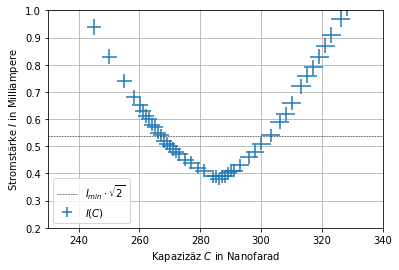

In [75]:
#plt.plot(C_inf_ohm/(1e-09), I_inf_ohm/(1e-03), color = "lightblue", zorder = 1)
plt.errorbar(C_inf_ohm/(1e-09), I_inf_ohm/(1e-03), xerr = u_C_inf_ohm/(1e-09), yerr = (u_I_inf_ohm/(1e-03)), marker = "", linestyle = "", zorder=2, label = "$I(C)$")
plt.axhline(y=(I_inf_ohm.min()*(np.sqrt(2)/(1e-03))), color="black", linestyle="--", linewidth = 0.5, label = r'$I_{min} \cdot \sqrt{2}$')
plt.xlim(230, 340)
plt.ylim(0.2,1)
plt.xlabel("Kapazizäz $C$ in Nanofarad")
plt.ylabel("Stromstärke $I$ in Milliampere")
plt.grid()
plt.legend()
plt.savefig('Parallelresonanzkreis inf Ohm.pdf')

In [76]:
c_0_inf_ohm = find_C_0_V2(C_inf_ohm, I_inf_ohm)
print(c_0_inf_ohm)
print("Die Induktivität beträgt: " +str(calc_L(c_0_inf_ohm)))
print("Die Unsicherheit dieses Wertes beträg:" +str(calc_u_L(c_0_inf_ohm, C_inf_ohm, u_C_inf_ohm)))
print()
print("Der Verlustwiderstand beträgt: " + str(calc_verlustwiderstand_par(C_inf_ohm, I_inf_ohm)))
ind_inf = calc_L(c_0_inf_ohm)
u_ind_inf = calc_u_L(c_0_inf_ohm, C_inf_ohm, u_C_inf_ohm)
r_v_inf = calc_verlustwiderstand_par(C_inf_ohm, I_inf_ohm)
u_r_v_inf = calc_u_verlust_par(C_inf_ohm, I_inf_ohm)
#Unsicherheiten der Punkte C_1 und C_2:
#"""
#Der ....
#"""

print("Die Unsicherheit des Verlustwiderstandes beträgt: " + str(calc_u_verlust_par(C_inf_ohm, I_inf_ohm)))
print()
print("Innenwiderstand = " + str((w_0**2 * calc_L(c_0_inf_ohm)**2)/calc_verlustwiderstand_par(C_inf_ohm, I_inf_ohm)))
print("Innenwiderstand Unsicherheit = " + str(calc_u_innen_wid_inf(ind_inf, u_ind_inf, r_v_inf, u_r_v_inf)))

2.8610000000000005e-07
Die Induktivität beträgt: 0.08853651139666005
Die Unsicherheit dieses Wertes beträg:0.002012461715408182

Der Verlustwiderstand beträgt: 8938.734605130343
Die Unsicherheit des Verlustwiderstandes beträgt: 185.94851117072585

Innenwiderstand = 34.62011487456314
Innenwiderstand Unsicherheit = 2.2474610595166005


### Diagramm zweite Messung parallel (9.9k Ohm)

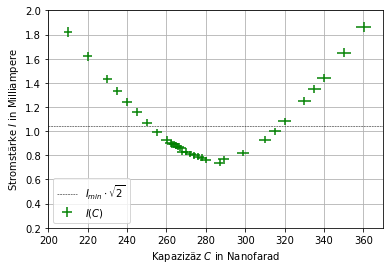

In [77]:
#plt.plot(C_9_9_k_ohm/(1e-09), I_9_9_k_ohm/(1e-03), color = "lightgreen", zorder = 1)
plt.errorbar(C_9_9_k_ohm/(1e-09), I_9_9_k_ohm/(1e-03), xerr = u_C_9_9_k_ohm/(1e-09), yerr = u_I_9_9_k_ohm/(1e-03), marker = "", linestyle = "", zorder=2, color="green", label = "$I(C)$")
plt.axhline(y=(I_9_9_k_ohm.min()*np.sqrt(2)/(1e-03)), color="black", linestyle="--", linewidth = 0.5, label = r'$I_{min} \cdot \sqrt{2}$')
plt.xlim(200, 370)
plt.ylim(0.2,2)
plt.xlabel("Kapazizäz $C$ in Nanofarad")
plt.ylabel("Stromstärke $I$ in Milliampere")
plt.grid()
plt.legend()
plt.savefig('Parallelresonanzkreis 9.9k Ohm.pdf')

In [78]:
c_0_9_9_k_ohm = find_C_0_V2(C_9_9_k_ohm, I_9_9_k_ohm)
print(c_0_9_9_k_ohm)
print("Die Induktivität beträgt: " +str(calc_L(c_0_9_9_k_ohm)))
ind_9_9 = calc_L(c_0_9_9_k_ohm)
u_ind_9_9 = calc_u_L(c_0_9_9_k_ohm, C_9_9_k_ohm, u_C_9_9_k_ohm)
print("Die Unsicherheit dieses Wertes beträg:" +str(calc_u_L(c_0_9_9_k_ohm, C_9_9_k_ohm, u_C_9_9_k_ohm)))
print()
print("Der Verlustwiderstand beträgt: " + str(calc_verlustwiderstand_par(C_9_9_k_ohm, I_9_9_k_ohm)))
print("Die Unsicherheit des Verlustwiderstandes beträgt: " + str(calc_u_verlust_par(C_9_9_k_ohm, I_9_9_k_ohm)))
r_v_9_9 = calc_verlustwiderstand_par(C_9_9_k_ohm, I_9_9_k_ohm)
u_r_v_9_9 = calc_u_verlust_par(C_9_9_k_ohm, I_9_9_k_ohm)
print()
print("Innenwiderstand = " + str(calc_innen_wid_par(ind_9_9, wid_9_9_k_ohm, r_v_9_9)))
print("Unsicherheit davon: " + str(calc_u_innen_wid_par(ind_9_9, u_ind_9_9, wid_9_9_k_ohm, u_9_9_k_ohm, r_v_9_9, u_r_v_9_9)))

2.871e-07
Die Induktivität beträgt: 0.08822812926013392
Die Unsicherheit dieses Wertes beträg:0.0020054520960581007

Der Verlustwiderstand beträgt: 4790.95518166481
Die Unsicherheit des Verlustwiderstandes beträgt: 114.99529877791288

Innenwiderstand = 33.38180710019399
Unsicherheit davon: 2.2674879465878632


### Diagramm dritte Messung parallel (2k Ohm)

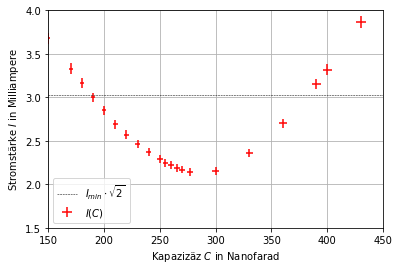

In [79]:
#plt.plot(C_2_k_ohm/(1e-09), I_2_k_ohm/(1e-03), color = "coral", zorder = 1)
plt.errorbar(C_2_k_ohm/(1e-09), I_2_k_ohm/(1e-03), xerr = u_C_2_k_ohm/(1e-09), yerr = u_I_2_k_ohm/(1e-03), marker = "", linestyle = "", zorder=2, color="red", label = "$I(C)$")
plt.axhline(y=(I_2_k_ohm.min()*np.sqrt(2)/(1e-03)), color="black", linestyle="--", linewidth = 0.5, label = r'$I_{min} \cdot \sqrt{2}$')
plt.xlim(150, 450)
plt.ylim(1.5,4)
plt.xlabel("Kapazizäz $C$ in Nanofarad")
plt.ylabel("Stromstärke $I$ in Milliampere")
plt.grid()
plt.legend()
plt.savefig('Parallelresonanzkreis 2k Ohm.pdf')

In [80]:
c_0_2_k_ohm = find_C_0_V2(C_2_k_ohm, I_2_k_ohm)
print(c_0_2_k_ohm)
print("Die Induktivität beträgt: " +str(calc_L(c_0_2_k_ohm)))
print("Die Unsicherheit dieses Wertes beträg:" +str(calc_u_L(c_0_2_k_ohm, C_2_k_ohm, u_C_2_k_ohm)))
ind_2 = calc_L(c_0_2_k_ohm)
u_ind_2 = calc_u_L(c_0_2_k_ohm, C_2_k_ohm, u_C_2_k_ohm)
print()
print("Der Verlustwiderstand beträgt: " + str(calc_verlustwiderstand_par(C_2_k_ohm, I_2_k_ohm)))
print("Die Unsicherheit des Verlustwiderstandes beträgt: " + str(calc_u_verlust_par(C_2_k_ohm, I_2_k_ohm)))
r_v_2 = calc_verlustwiderstand_par(C_2_k_ohm, I_2_k_ohm)
u_r_v_2 = calc_u_verlust_par(C_2_k_ohm, I_2_k_ohm)
print("Innenwiderstand: " + str(calc_innen_wid_par(ind_2, wid_2_k_ohm, r_v_2)))
print("Unsicherheit Innenwiderstand: " + str(calc_u_innen_wid_par(ind_2, u_ind_2, wid_2_k_ohm, u_2_k_ohm, r_v_2, u_r_v_2)))

2.7710000000000007e-07
Die Induktivität beträgt: 0.09141211082852559
Die Unsicherheit dieses Wertes beträg:0.002077824961307401

Der Verlustwiderstand beträgt: 1645.7590992199162
Die Unsicherheit des Verlustwiderstandes beträgt: 57.43680653653414
Innenwiderstand: 35.503376227063875
Unsicherheit Innenwiderstand: 7.223778548581187
